# Flood-Risk Prediction System for Northern Pakistan (KPK)
## Programming for AI - Major Assignment (Fall 2026)

| Field | Details |
|---|---|
| Course | Programming for Artificial Intelligence |
| Base paper | Sseguya, F. and Jun, K.-S. (2024). Deep Learning Ensemble for Flood Probability Analysis. *Water*, MDPI. https://doi.org/10.3390/w16213092 |
| Data | Open-Meteo archive API (weather), optional Open-Meteo Flood API (river discharge) |
| Tools | Python, pandas, NumPy, Matplotlib, scikit-learn (core models), TensorFlow/Keras (deep-learning extension) |



---
## 1. Problem definition
| Item | Definition |
|---|---|
| **Stakeholder** | A district-level disaster-management / emergency-planning office (for example PDMA/DDMA in Khyber Pakhtunkhwa) and the communities it serves. (Illustrative: no real organisation was consulted.) |
| **Problem** | Floods cause deaths and heavy losses in Pakistan (the 2022 floods are reported to have killed over 1,700 people). Offices need a simple, data-based indication of which days are likely to bring high flood risk, using only freely available weather data. |
| **Intended use** | **Decision support only:** a daily next-day "flood-risk" indication that helps staff decide where to look more closely. It is a classroom model, **not** an official warning system. |
| **Target variable** | `flood` = 1 if the next day is a *flood-risk day*, otherwise 0. A flood-risk day is a day in the top 5% of the **training period** for calculated runoff (default) or simulated river discharge (optional). This is a model-derived indicator, **not a verified river flood**. |
| **Input features** | The previous 30 days of: rainfall, estimated runoff, mean temperature, 7/14/30-day rainfall sums, 7-day runoff mean, and day-of-year (sin/cos) seasonality. |
| **Success criterion 1** | Recall of at least **70%**: the model catches at least 70% of flood-risk days in the untouched test years (2021-2024). Missing a flood is the costly mistake. |
| **Success criterion 2** | False-alarm rate of at most **15%**: no more than 15% of normal days are wrongly flagged, so staff do not stop trusting the signal. |

Both criteria are checked automatically in Section 8. If they are not met, the notebook says so.

**Notebook structure:** 1 Problem | 2 Setup and data | 3 Preprocessing | 4 Dataset audit | 5 EDA | 6 Core ML experiments (scikit-learn) |
7 Deep-learning extension | 8 Evaluation | 9 2022 analysis and explainability | 10 Testing and edge cases | 11 Demo | 12 Recommendation, limitations, project log

---
## 2. Setup and data collection

In [ ]:
import subprocess, sys
_r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openmeteo-requests", "requests-cache", "retry-requests", "imbalanced-learn"],
                    capture_output=True, text=True)
print("Packages installed." if _r.returncode == 0 else "Install problem:\n" + _r.stderr[-500:])

Packages installed.


In [ ]:
import os, time, json, warnings, datetime as dt, importlib.metadata as md
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import requests
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, precision_score, recall_score, f1_score,
                             fbeta_score, accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report, roc_curve)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.signal import savgol_filter
from numpy.lib.stride_tricks import sliding_window_view

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.3})
COLORS = ['#1F497D', '#2E75B6', '#E74C3C', '#27AE60', '#F39C12', '#8E44AD', '#7F8C8D', '#16A085']

In [ ]:
# ---------------- configuration (edit here) ----------------
QUICK = os.environ.get('QUICK_TEST') == '1'                      # fast dry run (used only for testing the code)
RUN_DL = os.environ.get('RUN_DL', '1') == '1'                    # False = skip the deep-learning extension (saves time)
LOCATIONS = {                                                     # name: (latitude, longitude) - check/adjust these coordinates
    'Havelian':     (34.05, 73.16),
    'Mingora_Swat': (34.78, 72.36),
    'Nowshera':     (34.02, 71.98),
    'Muzaffarabad': (34.37, 73.47),
}
LABEL_SOURCE = os.environ.get('LABEL_SOURCE', 'runoff')           # 'runoff' (default) or 'discharge' (GloFAS river discharge)
START_DATE = '1984-01-01' if LABEL_SOURCE == 'discharge' else '1960-01-01'
END_DATE = '2024-12-31'
TRAIN_END, VAL_END = '2018-12-31', '2020-12-31'                   # test period = after VAL_END (includes the 2022 floods)
SEQ_LEN, HORIZON, PCT = 30, 1, 0.95
ADD_SEASON = True
SC_RECALL, SC_FALSE_ALARM = 0.70, 0.15                            # success criteria (see Section 1)
COMPARE_DATASETS = True                                           # compare Open-Meteo rainfall with NASA POWER (needs internet)
EPOCHS, BATCH_SIZE, LR = 25, 256, 1e-3
RF_TREES = 100
TUNE_MAX_ROWS = 40000                                             # rows used for the time-series cross-validation (bounds run time)
if QUICK:
    LOCATIONS = dict(list(LOCATIONS.items())[:2]); START_DATE = '2000-01-01'; EPOCHS = 3; RF_TREES = 40; COMPARE_DATASETS = True
DATA_DIR, OUT_DIR = 'flood_data', 'flood_outputs'
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

DAILY_VARS = ['precipitation_sum', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'et0_fao_evapotranspiration']
COLS = ['rainfall_mm', 'temp_max_c', 'temp_min_c', 'wind_speed', 'evapotranspiration']


def validate_config(locations, label_source, start, end, train_end, val_end, seq_len, horizon, pct):
    """Check the configuration and raise a clear ValueError if something is wrong."""
    if not locations:
        raise ValueError('LOCATIONS is empty.')
    for name, (lat, lon) in locations.items():
        if not (-90 <= lat <= 90 and -180 <= lon <= 180):
            raise ValueError(f'Invalid coordinates for {name}: {lat}, {lon}')
    if label_source not in ('runoff', 'discharge'):
        raise ValueError("LABEL_SOURCE must be 'runoff' or 'discharge'.")
    d = [pd.Timestamp(x) for x in (start, train_end, val_end, end)]
    if not (d[0] < d[1] < d[2] < d[3]):
        raise ValueError('Dates must satisfy START < TRAIN_END < VAL_END < END.')
    if seq_len < 7 or horizon < 1 or not (0 < pct < 1):
        raise ValueError('Need SEQ_LEN >= 7, HORIZON >= 1 and 0 < PCT < 1.')
    return True


validate_config(LOCATIONS, LABEL_SOURCE, START_DATE, END_DATE, TRAIN_END, VAL_END, SEQ_LEN, HORIZON, PCT)

True

In [ ]:
def validate_weather_df(df, min_rows):
    """Validate and lightly clean a raw daily-weather DataFrame (index = date).
    Raises ValueError for bad input. Negative rain becomes 0; gaps of up to 3 days are interpolated."""
    if not isinstance(df, pd.DataFrame):
        raise ValueError('Weather data must be a pandas DataFrame.')
    missing = [c for c in COLS if c not in df.columns]
    if missing:
        raise ValueError(f'Missing required columns: {missing}')
    if len(df) < min_rows:
        raise ValueError(f'Need at least {min_rows} days of weather, got {len(df)}.')
    df = df[COLS].apply(pd.to_numeric, errors='coerce').sort_index()
    df = df[~df.index.duplicated(keep='first')]
    df.loc[df['rainfall_mm'] < 0, 'rainfall_mm'] = 0.0
    return df.interpolate(limit=3, limit_area='inside')


def quality_report(df):
    """Data-quality counts on the RAW download, before cleaning (used in the dataset audit)."""
    full = pd.date_range(df.index.min(), df.index.max(), freq='D')
    return {'rows': len(df), 'first date': df.index.min().date(), 'last date': df.index.max().date(),
            'missing values': int(df[COLS].isna().sum().sum()), 'duplicate dates': int(df.index.duplicated().sum()),
            'missing calendar days': int(len(full.difference(df.index))), 'negative rainfall values': int((df['rainfall_mm'] < 0).sum()),
            'dry days %': round(float((df['rainfall_mm'] == 0).mean() * 100), 1), 'max daily rain (mm)': round(float(df['rainfall_mm'].max()), 1)}


def fetch_weather(name, lat, lon):
    """Download daily weather for one location from Open-Meteo (cached as CSV). Raises an error instead of inventing data."""
    path = os.path.join(DATA_DIR, f'{name}_weather.csv')
    if os.path.exists(path):
        return pd.read_csv(path, parse_dates=['date']).set_index('date')
    import openmeteo_requests, requests_cache
    from retry_requests import retry
    client = openmeteo_requests.Client(session=retry(requests_cache.CachedSession('.cache', expire_after=-1), retries=5, backoff_factor=0.5))
    params = {'latitude': lat, 'longitude': lon, 'start_date': START_DATE, 'end_date': END_DATE, 'daily': DAILY_VARS, 'timezone': 'Asia/Karachi'}
    try:
        r = client.weather_api('https://archive-api.open-meteo.com/v1/archive', params=params)[0]
    except Exception as e:
        raise RuntimeError(f'Open-Meteo request failed for {name}: {e}\nIf it says a limit was exceeded, wait and run this cell again '
                           '(locations already downloaded are cached in flood_data/). No synthetic data is used.')
    d = r.Daily()
    offset = getattr(r, 'UtcOffsetSeconds', lambda: 0)()
    idx = pd.date_range(start=pd.to_datetime(d.Time() + offset, unit='s'), end=pd.to_datetime(d.TimeEnd() + offset, unit='s'),
                        freq=pd.Timedelta(seconds=d.Interval()), inclusive='left').round('D')
    df = pd.DataFrame({c: d.Variables(i).ValuesAsNumpy() for i, c in enumerate(COLS)}, index=idx)
    df.index.name = 'date'
    df.to_csv(path)
    json.dump({'source': 'Open-Meteo archive API', 'licence': 'CC BY 4.0 (attribution), free API for non-commercial use - check current terms',
               'location': name, 'lat': lat, 'lon': lon, 'start': START_DATE, 'end': END_DATE, 'access date': str(dt.date.today())},
              open(os.path.join(DATA_DIR, f'{name}_meta.json'), 'w'))
    time.sleep(2)
    return df


def fetch_discharge(name, lat, lon):
    """Simulated river discharge (GloFAS) from the Open-Meteo Flood API. Used only when LABEL_SOURCE == 'discharge'."""
    path = os.path.join(DATA_DIR, f'{name}_discharge.csv')
    if os.path.exists(path):
        return pd.read_csv(path, parse_dates=['date']).set_index('date')
    resp = requests.get('https://flood-api.open-meteo.com/v1/flood', timeout=120,
                        params={'latitude': lat, 'longitude': lon, 'start_date': START_DATE, 'end_date': END_DATE, 'daily': 'river_discharge'})
    resp.raise_for_status()
    j = resp.json()['daily']
    df = pd.DataFrame({'date': pd.to_datetime(j['time']), 'river_discharge': j['river_discharge']}).set_index('date')
    if df['river_discharge'].notna().mean() < 0.9 or df['river_discharge'].nunique() < 20:
        raise RuntimeError(f'No usable river-discharge series at {name} (the API returns the largest river within ~5 km). '
                           'Choose another coordinate or use LABEL_SOURCE = "runoff".')
    df.to_csv(path); time.sleep(2)
    return df


raw, quality = {}, {}
for name, (lat, lon) in LOCATIONS.items():
    w = fetch_weather(name, lat, lon)
    quality[name] = quality_report(w)
    w = validate_weather_df(w, min_rows=500)
    if LABEL_SOURCE == 'discharge':
        w = w.join(fetch_discharge(name, lat, lon), how='inner')
    raw[name] = w
    print(f'{name:<14} rows: {len(w):,}  period: {w.index.min().date()} to {w.index.max().date()}')
print('Label source:', LABEL_SOURCE)

Havelian       rows: 23,742  period: 1960-01-01 to 2024-12-31
Mingora_Swat   rows: 23,742  period: 1960-01-01 to 2024-12-31
Nowshera       rows: 23,742  period: 1960-01-01 to 2024-12-31
Muzaffarabad   rows: 23,742  period: 1960-01-01 to 2024-12-31
Label source: runoff


### 2.1 Dataset comparison (why Open-Meteo?)
Three candidate sources were compared before choosing one.

| | **Open-Meteo archive (chosen)** | **NASA POWER (daily)** | **Open-Meteo Flood API (GloFAS)** |
|---|---|---|---|
| What it gives | Daily rainfall, temperature, wind, evapotranspiration | Daily meteorology and solar data (rainfall = `PRECTOTCORR`) | Simulated daily river discharge |
| Access | Free API, no key | Free API, no key | Free API, no key |
| Coverage | Reanalysis-based history (many decades) | Meteorology from 1981, about 0.5 degree (~55 km) grid | From 1984, ~5 km grid |
| Strength | Long record, several weather variables in one call, easy Python access | Well-known NASA source, global | Closest to a flood signal (river flow) |
| Weakness | Reanalysis, not rain-gauge data; resolution changes with period | Coarse grid, so local heavy rain is smoothed | **Simulated**, not gauge data; returns the largest river in a ~5 km cell, may be unusable for small streams |
| Licence / access | CC BY 4.0 attribution; free API for non-commercial use (check current terms) | Free to use with acknowledgement (check POWER data-use guidance) | Same terms as Open-Meteo |

**Decision:** Open-Meteo archive is the main source (long history, all needed variables, no API key). Rainfall is cross-checked against NASA POWER below.
The Flood API is kept as an optional label source (`LABEL_SOURCE = "discharge"`). *Please re-check every licence and coverage statement on the providers' websites before citing it in your report.*

In [ ]:
def fetch_nasa_power_rain(name, lat, lon):
    """Daily rainfall (PRECTOTCORR, mm/day) from NASA POWER for the overlap period (meteorology starts in 1981)."""
    start = max(pd.Timestamp(START_DATE), pd.Timestamp('1981-01-01')).strftime('%Y%m%d')
    r = requests.get('https://power.larc.nasa.gov/api/temporal/daily/point', timeout=180,
                     params={'parameters': 'PRECTOTCORR', 'community': 'AG', 'latitude': lat, 'longitude': lon,
                             'start': start, 'end': END_DATE.replace('-', ''), 'format': 'JSON'})
    r.raise_for_status()
    s = pd.Series(r.json()['properties']['parameter']['PRECTOTCORR'], dtype=float)
    s.index = pd.to_datetime(s.index, format='%Y%m%d')
    return s.where(s > -990).rename('nasa_rain_mm')          # -999 marks missing values


comparison = None
if COMPARE_DATASETS:
    try:
        nm = list(LOCATIONS)[0]
        both = raw[nm][['rainfall_mm']].join(fetch_nasa_power_rain(nm, *LOCATIONS[nm]), how='inner').dropna()
        top = lambda s: s >= s.quantile(0.95)
        a, b = top(both['rainfall_mm']), top(both['nasa_rain_mm'])
        comparison = pd.DataFrame({'Open-Meteo': [both['rainfall_mm'].mean() * 365.25, (both['rainfall_mm'] > 1).mean() * 100, both['rainfall_mm'].max()],
                                   'NASA POWER': [both['nasa_rain_mm'].mean() * 365.25, (both['nasa_rain_mm'] > 1).mean() * 100, both['nasa_rain_mm'].max()]},
                                  index=['mean annual rainfall (mm)', 'rainy days (>1 mm) %', 'max daily rainfall (mm)']).round(1)
        print(f'Empirical comparison at {nm} ({len(both):,} common days):'); print(comparison.to_string())
        print(f"Daily correlation: {both['rainfall_mm'].corr(both['nasa_rain_mm']):.2f} | heavy-day (top 5%) overlap: {(a & b).sum() / max((a | b).sum(), 1) * 100:.0f}% of days flagged by either source")
        comparison.to_csv(f'{OUT_DIR}/dataset_comparison.csv')
    except Exception as e:
        print('NASA POWER cross-check skipped (this step is optional):', str(e)[:150])

Empirical comparison at Havelian (16,071 common days):
                           Open-Meteo  NASA POWER
mean annual rainfall (mm)      1577.8      1003.8
rainy days (>1 mm) %             43.0        27.3
max daily rainfall (mm)         213.6       426.6
Daily correlation: 0.36 | heavy-day (top 5%) overlap: 20% of days flagged by either source


---
## Literature Review

### Research Gap

Traditional flood prediction relied on physically-based models such as HEC-HMS, SWAT, and HEC-RAS. These require dense gauge sensor networks rarely available in developing countries, are computationally expensive, and cannot scale across diverse geographies. Prior machine learning methods (ARIMA, SVM, basic ANN) improved on this but could not capture spatial and temporal dependencies simultaneously.

The key research gap addressed by Sseguya and Jun (2024) is accurate flood prediction using only three minimal remotely-sensed variables (rainfall, runoff, temperature), removing dependency on expensive ground sensors while maintaining high accuracy — critical for data-scarce nations like Pakistan.

### Existing Methods and Their Limitations

| Method | How it Works | Limitation |
|---|---|---|
| ARIMA | Statistical autoregressive time-series model | Cannot capture nonlinear patterns; poor for extremes |
| SVM | Kernel-based classification on tabular data | Poor scalability; no temporal modeling |
| Basic ANN | Multi-layer perceptron with dense layers | Cannot model sequential time-dependencies |
| HEC-HMS | Physical water process simulation | Requires dense gauge networks; very expensive |
| Standalone CNN | 1D convolution on time series | Lacks temporal memory for long sequences |
| Standalone LSTM | Recurrent network for sequences | Slow; needs large data; no spatial feature extraction |

### Authors Contribution

Sseguya and Jun (2024) contribute three key innovations:
1. Minimal input design using only three remotely sensed variables
2. Deep Neural Network Ensemble (DNNE) combining FNN, CNN, and LSTM
3. Savitzky-Golay smoothing applied to flood probability output curves

### Authors Limitations (from the paper)

1. Model trained and tested only on the Nile River basin — not validated for other climates
2. Binary classification only — does not predict flood magnitude or affected area
3. Fixed 95th percentile threshold may not suit all seasonal and climatic conditions
4. No attention mechanism — model cannot identify which time steps are most flood-relevant
5. No class imbalance handling — flood events are rare and may be underdetected

---
## Section 3 - Preprocessing and Feature Engineering

Steps:
1. Compute runoff using the NRCS Curve Number method
2. Define flood events at the 95th percentile runoff threshold
3. Engineer rolling rainfall and runoff features
4. Normalize with StandardScaler
5. Create 30-day sliding window sequences
6. Apply SMOTE to handle class imbalance (improvement over original paper)

---
## 3. Preprocessing and feature engineering
Order matters (this prevents data leakage): features per location, **split by date first**, label threshold from the **training period only**,
scaler fitted on the **training period only**, then 30-day windows (each window belongs to the split of the day it predicts).
*Known simplification:* the Curve Number (CN = 75) is one typical value for mixed land use and is not calibrated per catchment.

In [ ]:
CN = 75
S_ret = (25400 / CN) - 254
Ia = 0.2 * S_ret
FEATURES = ['rainfall_mm', 'runoff_mm', 'temp_mean', 'rainfall_7d', 'rainfall_14d', 'rainfall_30d', 'runoff_7d'] + (['doy_sin', 'doy_cos'] if ADD_SEASON else [])
N_FEAT = len(FEATURES)
MIN_DAYS = SEQ_LEN + 29            # days of raw weather needed to build one prediction window (30-day rolling sums)


def add_features(df):
    """Add runoff (NRCS Curve Number), rolling rainfall features, mean temperature and seasonality. Rows with NaN are dropped."""
    df = df.copy()
    df['runoff_mm'] = np.where(df['rainfall_mm'] > Ia, (df['rainfall_mm'] - Ia) ** 2 / (df['rainfall_mm'] - Ia + S_ret), 0.0)
    df['rainfall_7d'] = df['rainfall_mm'].rolling(7).sum()
    df['rainfall_14d'] = df['rainfall_mm'].rolling(14).sum()
    df['rainfall_30d'] = df['rainfall_mm'].rolling(30).sum()
    df['runoff_7d'] = df['runoff_mm'].rolling(7).mean()
    df['temp_mean'] = (df['temp_max_c'] + df['temp_min_c']) / 2
    doy = df.index.dayofyear.values
    df['doy_sin'], df['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return df.dropna()


target_col = 'river_discharge' if LABEL_SOURCE == 'discharge' else 'runoff_mm'


def make_labels(df, col, pct=PCT, train_end=TRAIN_END, min_positive=20):
    """Flood-risk label: value >= the pct-quantile of the TRAINING period. Returns (labelled copy, threshold)."""
    train_part = df.loc[df.index <= train_end, col]
    if len(train_part) == 0:
        raise ValueError('No training-period rows to compute the flood threshold.')
    thr = max(float(train_part.quantile(pct)), 1e-6)         # 1e-6 stops an all-zero quantile from labelling every day
    out = df.copy(); out['flood'] = (out[col] >= thr).astype(int)
    if int(out.loc[out.index <= train_end, 'flood'].sum()) < min_positive:
        raise ValueError(f'Fewer than {min_positive} flood-risk days in the training period - check the data (a constant or dry series?).')
    return out, thr


data, thresholds = {}, {}
for name, w in raw.items():
    data[name], thresholds[name] = make_labels(add_features(w), target_col)
    unit = 'm3/s' if LABEL_SOURCE == 'discharge' else 'mm runoff'
    print(f'{name:<14} threshold (training-period {int(PCT * 100)}th pct): {thresholds[name]:.3f} {unit} | flood-risk days: {int(data[name].flood.sum()):,} ({data[name].flood.mean() * 100:.1f}%)')
if LABEL_SOURCE == 'runoff':
    print('NOTE: the label is the top-5% runoff days (heavy-rain days). It is NOT a verified river flood.')
first = list(data)[0]

Havelian       threshold (training-period 95th pct): 0.332 mm runoff | flood-risk days: 1,127 (4.8%)
Mingora_Swat   threshold (training-period 95th pct): 0.205 mm runoff | flood-risk days: 1,127 (4.8%)
Nowshera       threshold (training-period 95th pct): 0.000 mm runoff | flood-risk days: 1,168 (4.9%)
Muzaffarabad   threshold (training-period 95th pct): 0.040 mm runoff | flood-risk days: 1,203 (5.1%)
NOTE: the label is the top-5% runoff days (heavy-rain days). It is NOT a verified river flood.


In [ ]:
def make_sequences(df, loc_id, scaler):
    """Build 30-day windows. Window i uses days i..i+SEQ_LEN-1 and predicts the label HORIZON days after its last day."""
    Xs = scaler.transform(df[FEATURES].values).astype('float32')
    y = df['flood'].values
    n = len(df) - SEQ_LEN - HORIZON + 1
    if n <= 0:
        raise ValueError('Series too short for the chosen SEQ_LEN/HORIZON.')
    X = np.ascontiguousarray(np.transpose(sliding_window_view(Xs, SEQ_LEN, axis=0)[:n], (0, 2, 1)))
    tgt = np.arange(n) + SEQ_LEN - 1 + HORIZON
    return X, y[tgt], y[tgt - HORIZON], df.index[tgt], np.full(n, loc_id)


train_rows = np.vstack([df.loc[df.index <= TRAIN_END, FEATURES].values for df in data.values()])
scaler = StandardScaler().fit(train_rows)                      # fitted on the training period only
parts = [make_sequences(df, i, scaler) for i, df in enumerate(data.values())]
X_all = np.concatenate([p[0] for p in parts]); y_all = np.concatenate([p[1] for p in parts])
persist_all = np.concatenate([p[2] for p in parts]); date_all = pd.DatetimeIndex(np.concatenate([p[3] for p in parts]))
loc_all = np.concatenate([p[4] for p in parts]); loc_names = list(data)

m_tr, m_va, m_te = date_all <= TRAIN_END, (date_all > TRAIN_END) & (date_all <= VAL_END), date_all > VAL_END
X_train, y_train, date_train = X_all[m_tr], y_all[m_tr], date_all[m_tr]
X_val, y_val, persist_val = X_all[m_va], y_all[m_va], persist_all[m_va]
X_test, y_test, persist_test, date_test, loc_test = X_all[m_te], y_all[m_te], persist_all[m_te], date_all[m_te], loc_all[m_te]
split_table = pd.DataFrame({'samples': [len(y_train), len(y_val), len(y_test)], 'flood-risk days': [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
                            'share %': [round(y_train.mean() * 100, 2), round(y_val.mean() * 100, 2), round(y_test.mean() * 100, 2)],
                            'period': [f'{date_train.min().date()} to {date_train.max().date()}', f'{date_all[m_va].min().date()} to {date_all[m_va].max().date()}', f'{date_test.min().date()} to {date_test.max().date()}']},
                           index=['train', 'validation', 'test'])
print(split_table.to_string()); print('Window shape per sample:', X_train.shape[1:])

            samples  flood-risk days  share %                    period
train         85964             4304     5.01  1960-02-29 to 2018-12-31
validation     2924              116     3.97  2019-01-01 to 2020-12-31
test           5844              204     3.49  2021-01-01 to 2024-12-31
Window shape per sample: (30, 9)


---
## 4. Dataset audit and data dictionary
*Never fabricate data:* all values come from the API. The only derived columns are listed below.

In [ ]:
dictionary = pd.DataFrame([
    ('rainfall_mm', 'Daily total precipitation', 'mm', 'Open-Meteo `precipitation_sum`'),
    ('temp_max_c / temp_min_c', 'Daily maximum / minimum air temperature at 2 m', 'deg C', 'Open-Meteo'),
    ('wind_speed', 'Daily maximum wind speed at 10 m', 'km/h (API default)', 'Open-Meteo'),
    ('evapotranspiration', 'Reference evapotranspiration (FAO-56)', 'mm', 'Open-Meteo `et0_fao_evapotranspiration`'),
    ('runoff_mm', 'Estimated surface runoff (NRCS Curve Number, CN = 75)', 'mm', 'Derived from rainfall'),
    ('temp_mean', 'Mean of daily max and min temperature', 'deg C', 'Derived'),
    ('rainfall_7d / 14d / 30d', 'Rolling rainfall sums', 'mm', 'Derived'),
    ('runoff_7d', '7-day mean runoff', 'mm', 'Derived'),
    ('doy_sin / doy_cos', 'Day-of-year seasonality (sin/cos)', 'unitless', 'Derived'),
    ('river_discharge (optional)', 'Simulated river discharge (GloFAS)', 'm3/s', 'Open-Meteo Flood API'),
    ('flood (TARGET)', '1 = flood-risk day (top 5% of training-period runoff or discharge), 0 = normal day', '0/1', 'Derived label'),
], columns=['column', 'description', 'unit', 'source'])
print(dictionary.to_string(index=False)); dictionary.to_csv(f'{OUT_DIR}/data_dictionary.csv', index=False)

audit = pd.DataFrame(quality).T
print('\nData quality of the raw download (before cleaning):'); print(audit.to_string())
audit.to_csv(f'{OUT_DIR}/dataset_audit.csv')
print('\nClass balance per split (flood-risk days are the minority class):'); print(split_table.drop(columns=['period']).to_string())
meta_files = [f for f in os.listdir(DATA_DIR) if f.endswith('_meta.json')]
if meta_files:
    m = json.load(open(os.path.join(DATA_DIR, meta_files[0])))
    print(f"\nSource: {m['source']} | licence: {m['licence']} | access date: {m['access date']}")
print("""
Privacy: only weather data is used - no personal or identifiable information.
Limitations and possible bias: (1) only a few locations in one region; (2) reanalysis values, not rain-gauge measurements; (3) resolution differs
between older and newer periods; (4) the flood-risk label is derived from calculated runoff (or simulated discharge), not from verified flood records;
(5) flood-risk days are only about 5% of all days, so models see few examples.""")

                    column                                                                        description               unit                                  source
               rainfall_mm                                                          Daily total precipitation                 mm          Open-Meteo `precipitation_sum`
   temp_max_c / temp_min_c                                     Daily maximum / minimum air temperature at 2 m              deg C                              Open-Meteo
                wind_speed                                                   Daily maximum wind speed at 10 m km/h (API default)                              Open-Meteo
        evapotranspiration                                              Reference evapotranspiration (FAO-56)                 mm Open-Meteo `et0_fao_evapotranspiration`
                 runoff_mm                              Estimated surface runoff (NRCS Curve Number, CN = 75)                 mm                   Derived 

---
## 5. Exploratory data analysis (5 charts, each interpreted)

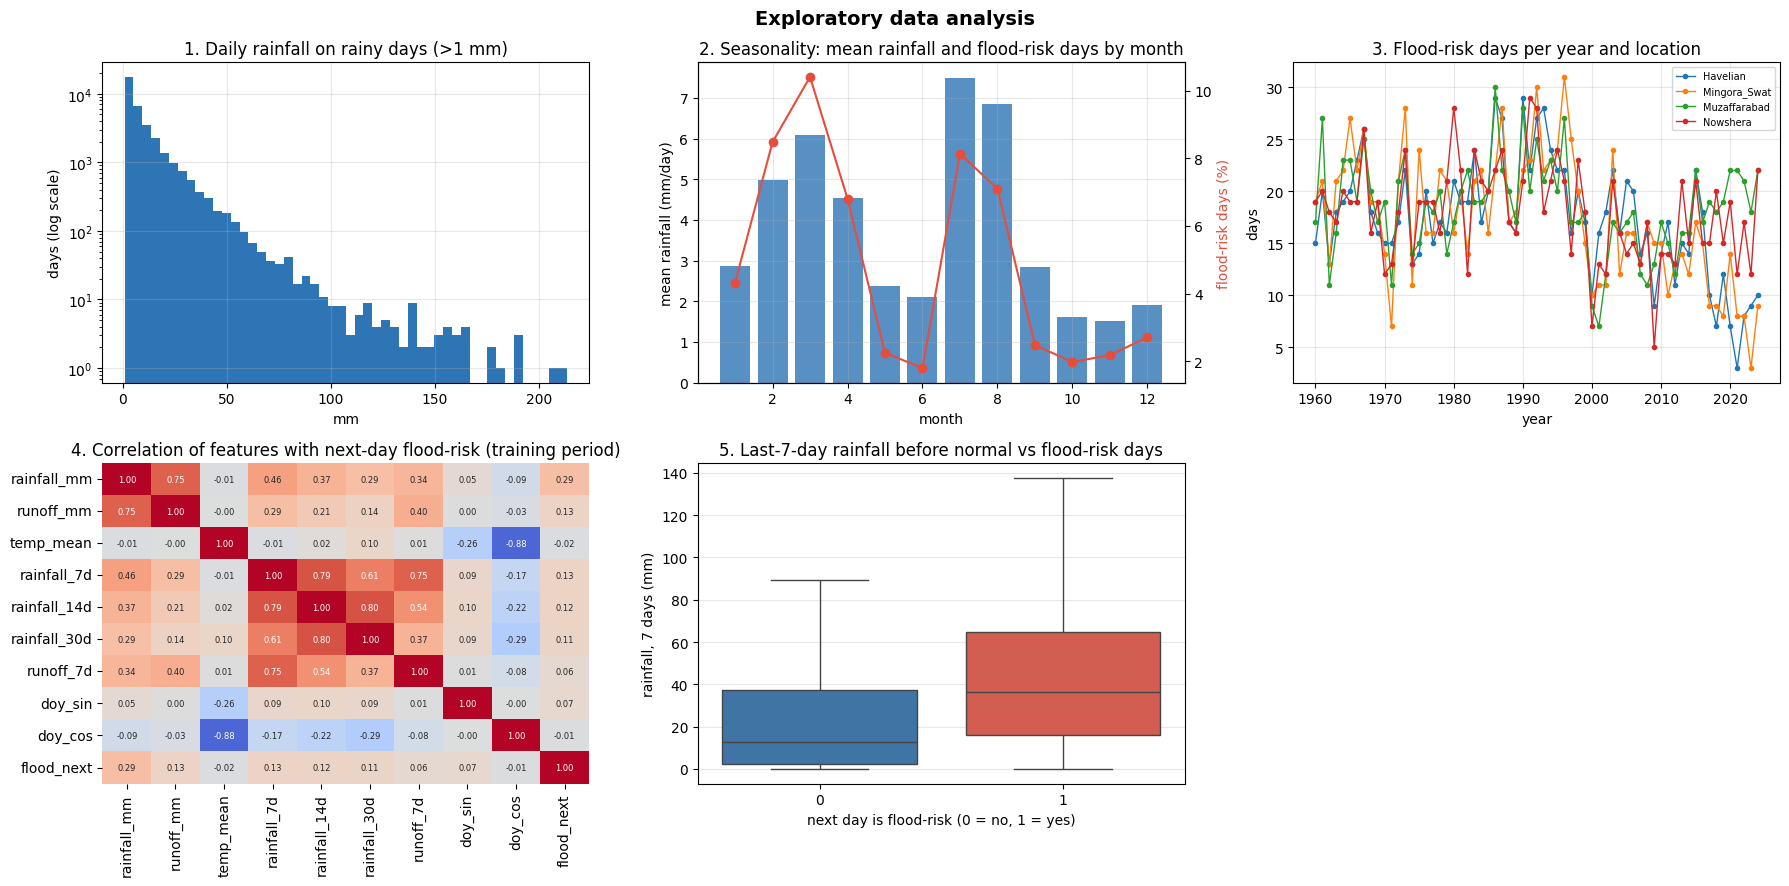

INTERPRETATION (computed from the data - write these in your own words in the report):
1. 37% of days have more than 1 mm of rain; the distribution is heavily skewed (log scale): most rainy days are light and a few are very heavy (maximum 214 mm).
2. Flood-risk days are concentrated in months [3, 2, 7]; 34% of all flood-risk days fall in June-September (monsoon season), so seasonality matters.
3. Flood-risk days per year vary strongly between years and locations (most in: Havelian: 1986, Mingora_Swat: 1996, Muzaffarabad: 1986, Nowshera: 1991). This is year-to-year variability, not proof of a trend.
4. Features most related to the next-day label: rainfall_mm (0.29), runoff_mm (0.13), rainfall_7d (0.13). Correlations are modest, so prediction from past weather alone is hard.
5. Median 7-day rainfall before flood-risk days: 36.5 mm vs 12.8 mm before normal days.


In [ ]:
pool = pd.concat([d.assign(location=n) for n, d in data.items()])
pool['month'], pool['year'] = pool.index.month, pool.index.year
for d in data.values():
    d['flood_next'] = d['flood'].shift(-HORIZON)
fig, axes = plt.subplots(2, 3, figsize=(18, 9)); axes = axes.ravel()
fig.suptitle('Exploratory data analysis', fontsize=14, fontweight='bold')
rainy = pool.loc[pool['rainfall_mm'] > 1, 'rainfall_mm']
axes[0].hist(rainy, bins=50, color=COLORS[1]); axes[0].set_yscale('log'); axes[0].set_title('1. Daily rainfall on rainy days (>1 mm)'); axes[0].set_xlabel('mm'); axes[0].set_ylabel('days (log scale)')
mon_rain = pool.groupby('month')['rainfall_mm'].mean(); mon_flood = pool.groupby('month')['flood'].mean() * 100
axes[1].bar(mon_rain.index, mon_rain.values, color=COLORS[1], alpha=0.8); axes[1].set_title('2. Seasonality: mean rainfall and flood-risk days by month'); axes[1].set_xlabel('month'); axes[1].set_ylabel('mean rainfall (mm/day)')
ax2 = axes[1].twinx(); ax2.plot(mon_flood.index, mon_flood.values, color=COLORS[2], marker='o'); ax2.set_ylabel('flood-risk days (%)', color=COLORS[2]); ax2.grid(False)
per_year = pool.groupby(['year', 'location'])['flood'].sum().unstack()
per_year.plot(ax=axes[2], marker='.', lw=1); axes[2].set_title('3. Flood-risk days per year and location'); axes[2].set_ylabel('days'); axes[2].legend(fontsize=7)
corr_df = pd.concat([d.loc[d.index <= TRAIN_END, FEATURES + ['flood_next']] for d in data.values()]).dropna()
sns.heatmap(corr_df.corr(), cmap='coolwarm', center=0, ax=axes[3], annot=True, fmt='.2f', annot_kws={'size': 6}, cbar=False)
axes[3].set_title('4. Correlation of features with next-day flood-risk (training period)'); axes[3].grid(False)
bp = corr_df.assign(flood_next=corr_df['flood_next'].astype(int))
sns.boxplot(data=bp, x='flood_next', y='rainfall_7d', ax=axes[4], palette=[COLORS[1], COLORS[2]], showfliers=False)
axes[4].set_title('5. Last-7-day rainfall before normal vs flood-risk days'); axes[4].set_xlabel('next day is flood-risk (0 = no, 1 = yes)'); axes[4].set_ylabel('rainfall, 7 days (mm)')
axes[5].axis('off')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/eda.png', dpi=120, bbox_inches='tight'); plt.show()

top_months = mon_flood.sort_values(ascending=False).head(3).index.tolist()
share_monsoon = pool.loc[pool['month'].isin([6, 7, 8, 9]), 'flood'].sum() / max(pool['flood'].sum(), 1) * 100
corr_target = corr_df.corr()['flood_next'].drop('flood_next').abs().sort_values(ascending=False)
yr_max = per_year.idxmax()
print('INTERPRETATION (computed from the data - write these in your own words in the report):')
print(f'1. {len(rainy) / len(pool) * 100:.0f}% of days have more than 1 mm of rain; the distribution is heavily skewed (log scale): most rainy days are light and a few are very heavy (maximum {pool.rainfall_mm.max():.0f} mm).')
print(f'2. Flood-risk days are concentrated in months {top_months}; {share_monsoon:.0f}% of all flood-risk days fall in June-September (monsoon season), so seasonality matters.')
print('3. Flood-risk days per year vary strongly between years and locations (most in: ' + ', '.join(f'{k}: {v}' for k, v in yr_max.items()) + '). This is year-to-year variability, not proof of a trend.')
print(f'4. Features most related to the next-day label: {", ".join(f"{k} ({v:.2f})" for k, v in corr_target.head(3).items())}. Correlations are modest, so prediction from past weather alone is hard.')
print(f'5. Median 7-day rainfall before flood-risk days: {bp.loc[bp.flood_next == 1, "rainfall_7d"].median():.1f} mm vs {bp.loc[bp.flood_next == 0, "rainfall_7d"].median():.1f} mm before normal days.')

---
## 6. Core machine-learning experiments (scikit-learn)
Rules used for every experiment: the **validation period** (2019-2020) is used to choose between options; the **test period** is touched only once, in Section 8.
Metric used to choose: **PR-AUC** (area under the precision-recall curve), because flood-risk days are rare and accuracy is misleading (a model that always says "no flood" scores about 95%).

| Experiment | What changes | Question |
|---|---|---|
| EXP1 | Baseline Logistic Regression | How well does a simple model do? |
| EXP2 | Feature set (last day only / window summary / window + extremes) | Do window features help? |
| EXP3 | Model type (Logistic Regression / Random Forest / Gradient Boosting) | Does a non-linear model help? |
| EXP4 | Imbalance handling (none / class weights / SMOTE) | How best to handle rare flood days? |
| EXP5 | Random Forest settings tuned with time-series cross-validation | Does tuning help? |

In [ ]:
def tab_features(X, kind='window'):
    """Turn 30-day windows (n, 30, F) into flat tabular features for scikit-learn models."""
    last = X[:, -1, :]
    if kind == 'basic':
        return last
    out = [last, X.mean(axis=1), X[:, -7:, :].mean(axis=1)]
    if kind == 'window_ext':
        ch = [FEATURES.index('rainfall_mm'), FEATURES.index('runoff_mm')]
        out += [X[:, :, ch].max(axis=1), X[:, :, ch].std(axis=1)]
    return np.concatenate(out, axis=1)


def best_threshold_f2(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
    return float(thr[int(np.nanargmax(f[:-1]))])


def threshold_for_recall(y, p, target):
    """Highest threshold that still reaches `target` recall on validation data (fewest false alarms); falls back to the best-F2 threshold."""
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else best_threshold_f2(y, p)


EXPERIMENTS = []


def log_experiment(exp, change, model, p_val):
    thr = best_threshold_f2(y_val, p_val)
    EXPERIMENTS.append({'experiment': exp, 'what changed': change, 'model': model, 'val PR-AUC': round(average_precision_score(y_val, p_val), 4),
                        'val ROC-AUC': round(roc_auc_score(y_val, p_val), 4), 'val recall (F2 threshold)': round(recall_score(y_val, (p_val >= thr).astype(int)), 3)})
    return EXPERIMENTS[-1]['val PR-AUC']


def make_rf(strategy, **params):
    """Random Forest pipeline; SMOTE (if chosen) is applied to training data only."""
    steps = [('smote', SMOTE(sampling_strategy=0.5, random_state=SEED) if strategy == 'smote' else 'passthrough'),
             ('rf', RandomForestClassifier(class_weight='balanced_subsample' if strategy == 'class_weight' else None, n_jobs=-1, random_state=SEED,
                                           **{'n_estimators': RF_TREES, 'min_samples_leaf': 5, **params}))]
    return ImbPipeline(steps)


# EXP1 - baseline
F_win = tab_features(X_train, 'window'); Fv_win = tab_features(X_val, 'window')
lr = LogisticRegression(max_iter=2000, class_weight='balanced').fit(F_win, y_train)
log_experiment('EXP1', 'Baseline (window features, class weights)', 'Logistic Regression', lr.predict_proba(Fv_win)[:, 1])

# EXP2 - feature sets
feat_scores = {}
for kind in ['basic', 'window', 'window_ext']:
    m = make_rf('class_weight').fit(tab_features(X_train, kind), y_train)
    feat_scores[kind] = log_experiment('EXP2', f'Feature set = {kind}', 'Random Forest', m.predict_proba(tab_features(X_val, kind))[:, 1])
BEST_FEAT = max(feat_scores, key=feat_scores.get)

# EXP3 - model type on the best feature set
Ft, Fv = tab_features(X_train, BEST_FEAT), tab_features(X_val, BEST_FEAT)
model_scores = {}
model_scores['Logistic Regression'] = log_experiment('EXP3', f'Model type (features = {BEST_FEAT})', 'Logistic Regression',
                                                     LogisticRegression(max_iter=2000, class_weight='balanced').fit(Ft, y_train).predict_proba(Fv)[:, 1])
model_scores['Random Forest'] = feat_scores[BEST_FEAT]
EXPERIMENTS.append({**EXPERIMENTS[[e['model'] == 'Random Forest' and e['what changed'] == f'Feature set = {BEST_FEAT}' for e in EXPERIMENTS].index(True)],
                    'experiment': 'EXP3', 'what changed': f'Model type (features = {BEST_FEAT})'})
hgb = HistGradientBoostingClassifier(max_iter=50 if QUICK else 200, learning_rate=0.1, class_weight='balanced', random_state=SEED).fit(Ft, y_train)
model_scores['Gradient Boosting'] = log_experiment('EXP3', f'Model type (features = {BEST_FEAT})', 'Hist Gradient Boosting', hgb.predict_proba(Fv)[:, 1])

# EXP4 - imbalance handling for the Random Forest
strat_scores = {}
for strat in ['none', 'class_weight', 'smote']:
    m = make_rf(strat).fit(Ft, y_train)
    strat_scores[strat] = log_experiment('EXP4', f'Imbalance handling = {strat}', 'Random Forest', m.predict_proba(Fv)[:, 1])
BEST_STRAT = max(strat_scores, key=strat_scores.get)

# EXP5 - tuning with time-series cross-validation (rows sorted by date; at most TUNE_MAX_ROWS most recent training rows)
order = np.argsort(date_train.values, kind='stable')[-TUNE_MAX_ROWS:]
grid = {'rf__n_estimators': [RF_TREES, RF_TREES * 2], 'rf__min_samples_leaf': [3, 10]} if not QUICK else {'rf__min_samples_leaf': [3, 10]}
gs = GridSearchCV(make_rf(BEST_STRAT), grid, scoring='average_precision', cv=TimeSeriesSplit(3), n_jobs=1, refit=True)
gs.fit(Ft[order], y_train[order])
rf_tuned = make_rf(BEST_STRAT, **{k.replace('rf__', ''): v for k, v in gs.best_params_.items()}).fit(Ft, y_train)       # refit on ALL training rows
log_experiment('EXP5', f'Tuned {gs.best_params_} (time-series CV), imbalance = {BEST_STRAT}', 'Random Forest (tuned)', rf_tuned.predict_proba(Fv)[:, 1])

exp_df = pd.DataFrame(EXPERIMENTS)
print(exp_df.to_string(index=False)); exp_df.to_csv(f'{OUT_DIR}/experiments_log.csv', index=False)
print(f'\nDecisions (validation data only): features = {BEST_FEAT} | imbalance handling = {BEST_STRAT} | tuned parameters = {gs.best_params_}')
print('Baseline = Logistic Regression (EXP1). Improved model = tuned Random Forest (EXP5).')

experiment                                                                                   what changed                  model  val PR-AUC  val ROC-AUC  val recall (F2 threshold)
      EXP1                                                      Baseline (window features, class weights)    Logistic Regression      0.1182       0.7818                      0.802
      EXP2                                                                            Feature set = basic          Random Forest      0.1296       0.7849                      0.647
      EXP2                                                                           Feature set = window          Random Forest      0.1297       0.7938                      0.776
      EXP2                                                                       Feature set = window_ext          Random Forest      0.1256       0.7916                      0.655
      EXP3                                                                 Model type (features

---
## 7. Deep-learning extension
The base paper uses deep learning (FNN, CNN, LSTM, ensemble), so these models are kept as an extension and compared on the same split and metrics.
They are not required by the core scikit-learn workflow above. Set `RUN_DL = False` in the configuration cell to skip this section and save time.
The CNN-LSTM-Attention model returns its **real attention scores** (the earlier version drew hand-made numbers).

In [ ]:
PRED = {}      # name -> function(windows (n, 30, F)) -> probability of a flood-risk day
PRED['Logistic Regression (baseline)'] = lambda X, m=lr: m.predict_proba(tab_features(X, 'window'))[:, 1]
PRED['Random Forest (improved)'] = lambda X, m=rf_tuned: m.predict_proba(tab_features(X, BEST_FEAT))[:, 1]
PRED['Hist Gradient Boosting'] = lambda X, m=hgb: m.predict_proba(tab_features(X, BEST_FEAT))[:, 1]
attn_viz, dl_models, histories = None, {}, {}

if RUN_DL:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
    from tensorflow.keras.optimizers import Adam
    tf.random.set_seed(SEED)
    INPUT_SHAPE = (SEQ_LEN, N_FEAT)

    def compile_model(model):
        model.compile(optimizer=Adam(LR), loss='binary_crossentropy', metrics=['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.AUC(name='pr_auc', curve='PR')])
        return model

    def build_fnn():
        inp = keras.Input(shape=INPUT_SHAPE)
        x = layers.Dense(128, activation='relu')(layers.Flatten()(inp)); x = layers.Dropout(0.3)(x); x = layers.Dense(64, activation='relu')(x); x = layers.Dropout(0.2)(x)
        return keras.Model(inp, layers.Dense(1, activation='sigmoid')(x), name='FNN')

    def build_cnn():
        inp = keras.Input(shape=INPUT_SHAPE)
        x = layers.Conv1D(32, 3, activation='relu', padding='same')(inp); x = layers.Conv1D(64, 3, activation='relu', padding='same')(x)
        x = layers.GlobalAveragePooling1D()(layers.Dropout(0.3)(layers.MaxPooling1D(2)(x))); x = layers.Dropout(0.2)(layers.Dense(32, activation='relu')(x))
        return keras.Model(inp, layers.Dense(1, activation='sigmoid')(x), name='CNN')

    def build_lstm():
        inp = keras.Input(shape=INPUT_SHAPE)
        x = layers.Dense(32, activation='relu')(layers.Dropout(0.3)(layers.LSTM(64)(inp)))
        return keras.Model(inp, layers.Dense(1, activation='sigmoid')(x), name='LSTM')

    def build_attn():
        """CNN-LSTM-Attention; also returns a second model that outputs the attention scores of the SAME trained layer."""
        inp = keras.Input(shape=INPUT_SHAPE)
        x = layers.Dropout(0.2)(layers.Conv1D(32, 3, activation='relu', padding='same')(inp))
        x = layers.Dropout(0.3)(layers.LSTM(64, return_sequences=True)(x))
        a_out, a_scores = layers.MultiHeadAttention(num_heads=2, key_dim=16)(x, x, return_attention_scores=True)
        x = layers.GlobalAveragePooling1D()(layers.LayerNormalization()(layers.Add()([x, a_out])))
        x = layers.Dropout(0.2)(layers.Dense(32, activation='relu')(x))
        return keras.Model(inp, layers.Dense(1, activation='sigmoid')(x), name='CNN_LSTM_Attention'), keras.Model(inp, a_scores, name='attention_scores')

    def make_train_set(strategy):
        if strategy == 'smote':       # flattened windows -> synthetic windows are interpolations, not real weather (treated as an experiment)
            Xs, ys = SMOTE(sampling_strategy=0.5, random_state=SEED, k_neighbors=5).fit_resample(X_train.reshape(len(X_train), -1), y_train)
            return Xs.reshape(-1, SEQ_LEN, N_FEAT).astype('float32'), ys, None
        if strategy == 'class_weight':
            n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
            return X_train, y_train, {0: len(y_train) / (2 * n0), 1: len(y_train) / (2 * n1)}
        return X_train, y_train, None

    def fit_model(model, strategy):
        Xt, yt, cw = make_train_set(strategy)
        cbs = [EarlyStopping(monitor='val_pr_auc', mode='max', patience=5, restore_best_weights=True),
               ReduceLROnPlateau(monitor='val_pr_auc', mode='max', factor=0.5, patience=3, min_lr=1e-6)]
        t0 = time.time()
        h = model.fit(Xt, yt, validation_data=(X_val, y_val), epochs=EPOCHS, batch_size=BATCH_SIZE, class_weight=cw, callbacks=cbs, verbose=0)
        return h, time.time() - t0, len(Xt)

    rows = []
    for strat in ['none', 'class_weight', 'smote']:                 # imbalance strategy for deep models, chosen on validation PR-AUC (fast CNN)
        keras.utils.set_random_seed(SEED); m = compile_model(build_cnn()); h, secs, n_used = fit_model(m, strat)
        pv = m.predict(X_val, verbose=0).ravel()
        rows.append({'strategy': strat, 'training samples': n_used, 'val PR-AUC': round(average_precision_score(y_val, pv), 4), 'seconds': round(secs)})
    dl_strat = pd.DataFrame(rows).set_index('strategy'); print(dl_strat)
    DL_STRATEGY = dl_strat['val PR-AUC'].idxmax(); print('Deep-learning imbalance strategy chosen on validation data:', DL_STRATEGY)
    for name in ['FNN', 'CNN', 'LSTM', 'CNN-LSTM-Attn']:
        keras.utils.set_random_seed(SEED)
        if name == 'CNN-LSTM-Attn':
            m, attn_viz = build_attn(); m = compile_model(m)
        else:
            m = compile_model({'FNN': build_fnn, 'CNN': build_cnn, 'LSTM': build_lstm}[name]())
        h, secs, n_used = fit_model(m, DL_STRATEGY); dl_models[name], histories[name] = m, h
        PRED[name] = lambda X, m=m: m.predict(X, batch_size=2048, verbose=0).ravel()
        print(f'{name:<14} {secs:.0f}s | epochs {len(h.history["loss"])} | training samples {n_used:,} | best val PR-AUC {max(h.history["val_pr_auc"]):.4f}')
    PRED['DNNE (FNN+CNN+LSTM)'] = lambda X: np.mean([PRED[k](X) for k in ('FNN', 'CNN', 'LSTM')], axis=0)
else:
    print('Deep-learning extension skipped (RUN_DL = False).')

              training samples  val PR-AUC  seconds
strategy                                           
none                     85964      0.1298       74
class_weight             85964      0.1358       25
smote                   122490      0.1177       26
Deep-learning imbalance strategy chosen on validation data: class_weight
FNN            19s | epochs 8 | training samples 85,964 | best val PR-AUC 0.1291
CNN            25s | epochs 9 | training samples 85,964 | best val PR-AUC 0.1324
LSTM           57s | epochs 16 | training samples 85,964 | best val PR-AUC 0.1352
CNN-LSTM-Attn  32s | epochs 6 | training samples 85,964 | best val PR-AUC 0.0962


---
## 8. Evaluation on the untouched test period (2021-2024)
* Every model is scored on **raw probabilities** (no smoothing).
* The decision threshold is chosen on the **validation period**: the highest threshold that still reaches the 70% recall target (fewest false alarms), or the best-F2 threshold if the target cannot be reached.
* **Which metric matters most:** recall (catching flood-risk days) because a missed flood costs far more than a false alarm; precision and the false-alarm rate limit how many false alarms staff must handle;
  accuracy is shown but is misleading here because about 95% of days are normal.
* The final model is selected by **validation PR-AUC**, never by test results.

In [ ]:
def score(y, p, thr):
    pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'threshold': round(float(thr), 3), 'accuracy': accuracy_score(y, pred), 'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred, zero_division=0),
            'F1': f1_score(y, pred, zero_division=0), 'F2': fbeta_score(y, pred, beta=2, zero_division=0), 'false alarm rate': fp / max(fp + tn, 1),
            'balanced acc': balanced_accuracy_score(y, pred), 'PR-AUC': average_precision_score(y, p), 'ROC-AUC': roc_auc_score(y, p)}


p_val = {k: fn(X_val) for k, fn in PRED.items()}; p_test = {k: fn(X_test) for k, fn in PRED.items()}
p_val['Persistence (baseline)'] = persist_val.astype(float); p_test['Persistence (baseline)'] = persist_test.astype(float)
THR = {k: (0.5 if k.startswith('Persistence') else threshold_for_recall(y_val, p_val[k], SC_RECALL)) for k in p_test}
rows = []
for k in p_test:
    r = score(y_test, p_test[k], THR[k]); r['val PR-AUC'] = average_precision_score(y_val, p_val[k]); r['Model'] = k
    r['SC1 recall>=70%'] = 'met' if r['recall'] >= SC_RECALL else 'not met'; r['SC2 false alarms<=15%'] = 'met' if r['false alarm rate'] <= SC_FALSE_ALARM else 'not met'
    rows.append(r)
results_df = pd.DataFrame(rows).set_index('Model')
print(f'Test set: {len(y_test):,} days, {int(y_test.sum())} flood-risk days ({y_test.mean() * 100:.1f}%). "Always no flood" would score {100 - y_test.mean() * 100:.1f}% accuracy.\n')
print(results_df.round(3).to_string()); results_df.round(4).to_csv(f'{OUT_DIR}/test_results.csv')
candidates = [k for k in results_df.index if 'baseline' not in k or k.startswith('Logistic')]
FINAL = results_df.loc[candidates, 'val PR-AUC'].idxmax()
print('\nFINAL MODEL (best validation PR-AUC, not test):', FINAL)

Test set: 5,844 days, 204 flood-risk days (3.5%). "Always no flood" would score 96.5% accuracy.

                                threshold  accuracy  precision  recall     F1     F2  false alarm rate  balanced acc  PR-AUC  ROC-AUC  val PR-AUC SC1 recall>=70% SC2 false alarms<=15%
Model                                                                                                                                                                                  
Logistic Regression (baseline)      0.388     0.732      0.087   0.706  0.155  0.292             0.267         0.719   0.146    0.785       0.118             met               not met
Random Forest (improved)            0.055     0.800      0.119   0.740  0.206  0.363             0.198         0.771   0.150    0.834       0.141             met               not met
Hist Gradient Boosting              0.503     0.820      0.124   0.686  0.210  0.360             0.175         0.756   0.162    0.842       0.144         not met      

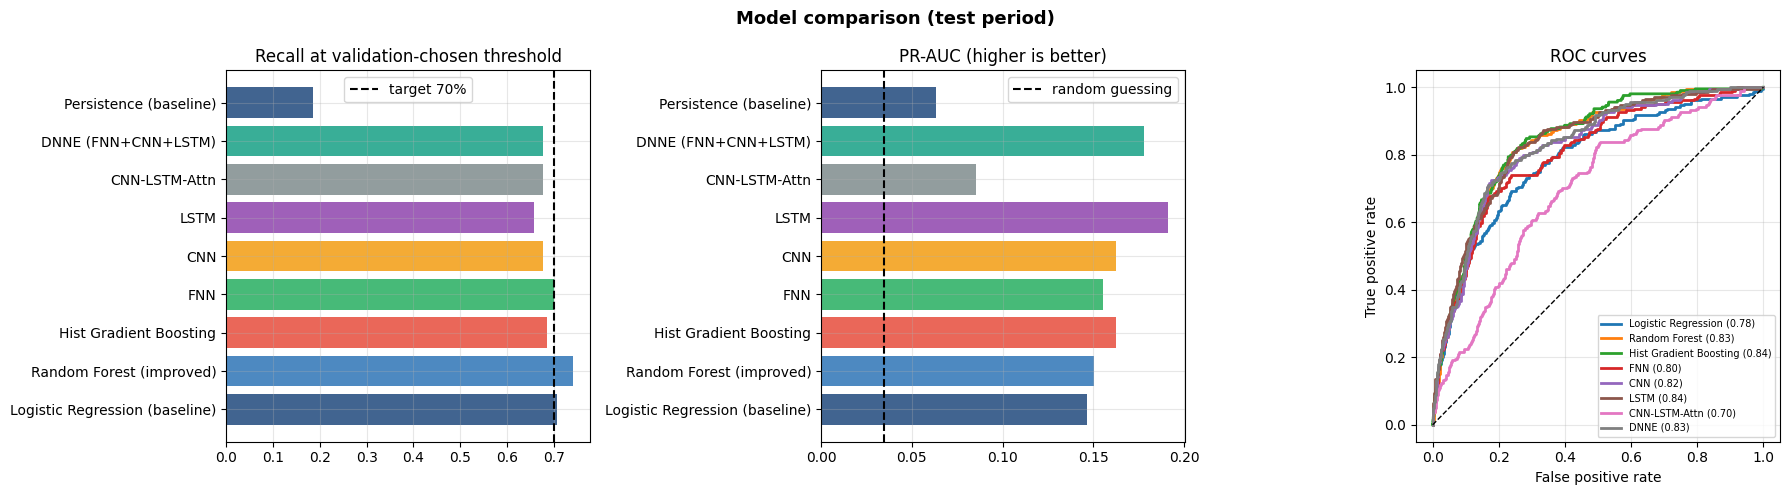

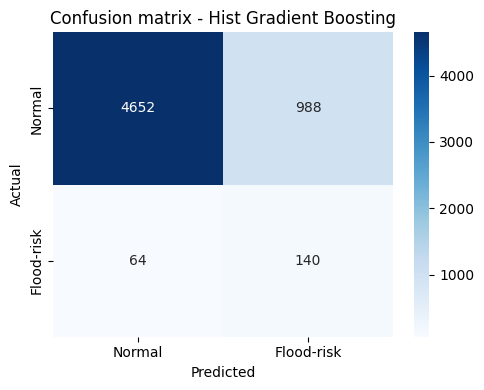

              precision    recall  f1-score   support

      Normal       0.99      0.82      0.90      5640
  Flood-risk       0.12      0.69      0.21       204

    accuracy                           0.82      5844
   macro avg       0.56      0.76      0.55      5844
weighted avg       0.96      0.82      0.87      5844

Per-location results for Hist Gradient Boosting:
    location  test days  flood-risk days  caught  recall  precision  false alarms
    Havelian       1461               30      23   0.767      0.096           216
Mingora_Swat       1461               28      20   0.714      0.073           254
    Nowshera       1461               63      40   0.635      0.139           247
Muzaffarabad       1461               83      57   0.687      0.174           271

SUCCESS CRITERIA (final model, test period):
  SC1 recall >= 70%:           68.6%  -> NOT MET
  SC2 false-alarm rate <= 15%:  17.5%  -> NOT MET
Improved vs baseline (Logistic Regression): PR-AUC 0.150 vs 0.146; re

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5)); fig.suptitle('Model comparison (test period)', fontsize=13, fontweight='bold')
order_ = list(results_df.index)
axes[0].barh(order_, results_df['recall'], color=COLORS[:len(order_)], alpha=0.85); axes[0].axvline(SC_RECALL, color='k', ls='--', label='target 70%'); axes[0].set_title('Recall at validation-chosen threshold'); axes[0].legend()
axes[1].barh(order_, results_df['PR-AUC'], color=COLORS[:len(order_)], alpha=0.85); axes[1].axvline(y_test.mean(), color='k', ls='--', label='random guessing'); axes[1].set_title('PR-AUC (higher is better)'); axes[1].legend()
for k in order_:
    if k.startswith('Persistence'): continue
    fpr_, tpr_, _ = roc_curve(y_test, p_test[k]); axes[2].plot(fpr_, tpr_, lw=2, label=f"{k.split(' (')[0]} ({results_df.loc[k, 'ROC-AUC']:.2f})")
axes[2].plot([0, 1], [0, 1], 'k--', lw=1); axes[2].set_title('ROC curves'); axes[2].set_xlabel('False positive rate'); axes[2].set_ylabel('True positive rate'); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/model_comparison.png', dpi=120, bbox_inches='tight'); plt.show()

pred_final = (p_test[FINAL] >= THR[FINAL]).astype(int)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, pred_final), annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=['Normal', 'Flood-risk'], yticklabels=['Normal', 'Flood-risk'])
ax.set_title(f'Confusion matrix - {FINAL}'); ax.set_ylabel('Actual'); ax.set_xlabel('Predicted'); ax.grid(False)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=120, bbox_inches='tight'); plt.show()
print(classification_report(y_test, pred_final, target_names=['Normal', 'Flood-risk'], zero_division=0))

per_loc = []
for i, nm in enumerate(loc_names):
    k = loc_test == i; yy, pp = y_test[k], pred_final[k]
    per_loc.append({'location': nm, 'test days': int(k.sum()), 'flood-risk days': int(yy.sum()), 'caught': int(((yy == 1) & (pp == 1)).sum()), 'recall': round(recall_score(yy, pp, zero_division=0), 3),
                    'precision': round(precision_score(yy, pp, zero_division=0), 3), 'false alarms': int(((yy == 0) & (pp == 1)).sum())})
print(f'Per-location results for {FINAL}:'); print(pd.DataFrame(per_loc).to_string(index=False))

fr = results_df.loc[FINAL]
sc1, sc2 = fr['recall'] >= SC_RECALL, fr['false alarm rate'] <= SC_FALSE_ALARM
print('\nSUCCESS CRITERIA (final model, test period):')
print(f"  SC1 recall >= {SC_RECALL:.0%}:           {fr['recall']:.1%}  -> {'MET' if sc1 else 'NOT MET'}")
print(f"  SC2 false-alarm rate <= {SC_FALSE_ALARM:.0%}:  {fr['false alarm rate']:.1%}  -> {'MET' if sc2 else 'NOT MET'}")
base = results_df.loc['Logistic Regression (baseline)']
print(f"Improved vs baseline (Logistic Regression): PR-AUC {results_df.loc['Random Forest (improved)', 'PR-AUC']:.3f} vs {base['PR-AUC']:.3f}; recall {results_df.loc['Random Forest (improved)', 'recall']:.2f} vs {base['recall']:.2f}.")

---
## 9. 2022 monsoon analysis and explainability
**2022 monsoon:** the "actual" days below are *flood-risk days defined by the label*, **not verified flood records**, so this is an analysis of heavy-runoff (or simulated high-discharge) days
and not independent proof that the real 2022 flood was detected. A real validation would compare against documented flood dates or river-gauge data.

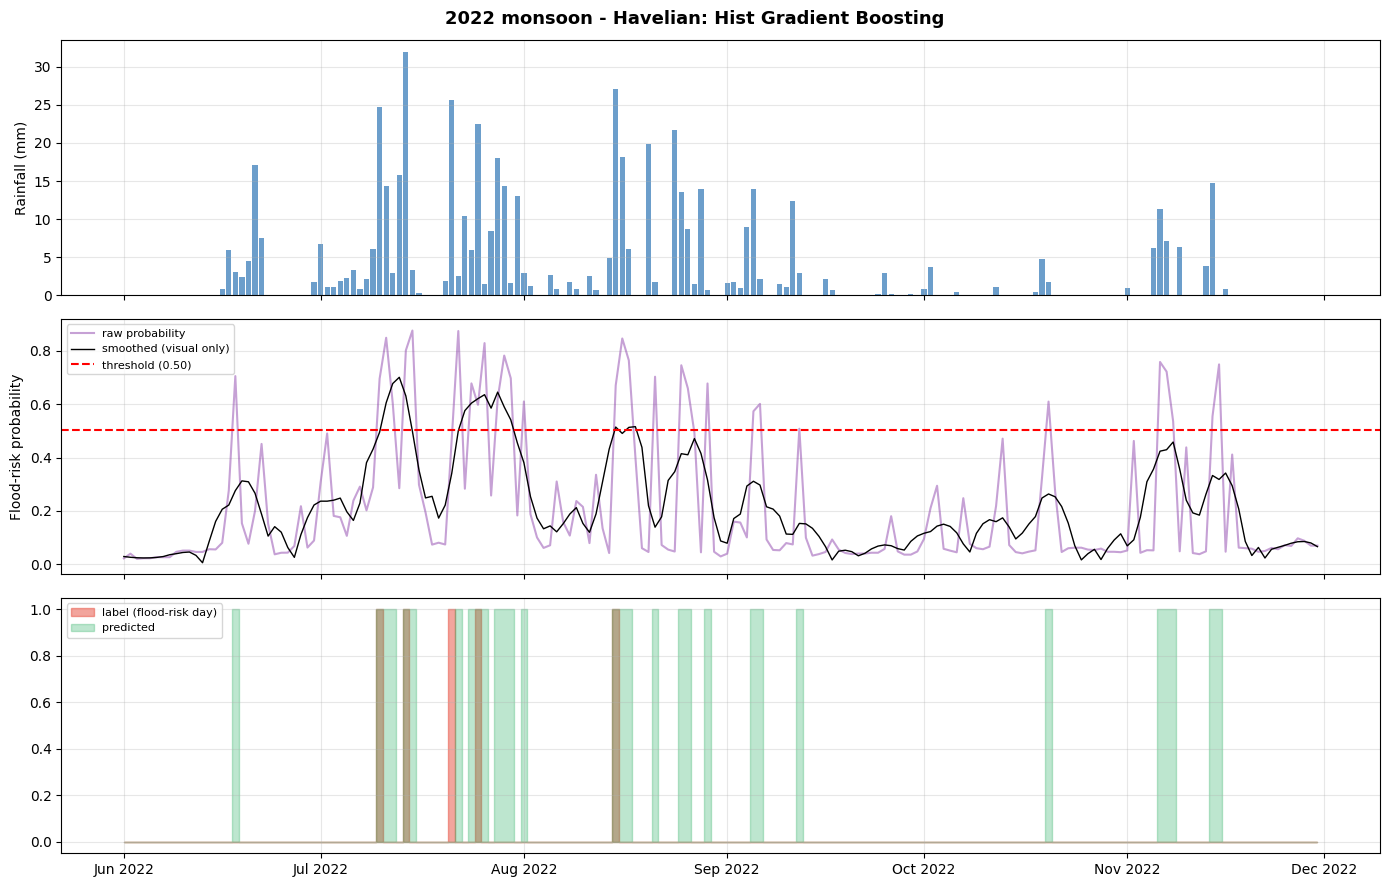

Flood-risk days (by label): 5 | caught: 4 (80%) | false alarms: 26 | days analysed: 183


In [ ]:
k = (loc_test == 0) & (date_test >= '2022-06-01') & (date_test <= '2022-11-30')
period = pd.DataFrame({'actual': y_test[k], 'prob': p_test[FINAL][k]}, index=date_test[k]); period['pred'] = (period['prob'] >= THR[FINAL]).astype(int)
period['rain'] = data[first]['rainfall_mm'].reindex(period.index).values
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True); fig.suptitle(f'2022 monsoon - {first}: {FINAL}', fontsize=13, fontweight='bold')
axes[0].bar(period.index, period['rain'], color=COLORS[1], alpha=0.7); axes[0].set_ylabel('Rainfall (mm)')
sm = np.clip(savgol_filter(period['prob'].values, 11, 3), 0, 1) if len(period) > 11 else period['prob'].values
axes[1].plot(period.index, period['prob'], color=COLORS[5], alpha=0.5, label='raw probability'); axes[1].plot(period.index, sm, color='k', lw=1, label='smoothed (visual only)')
axes[1].axhline(THR[FINAL], color='red', ls='--', label=f'threshold ({THR[FINAL]:.2f})'); axes[1].set_ylabel('Flood-risk probability'); axes[1].legend(fontsize=8)
axes[2].fill_between(period.index, period['actual'], alpha=0.5, color=COLORS[2], step='mid', label='label (flood-risk day)'); axes[2].fill_between(period.index, period['pred'], alpha=0.3, color=COLORS[3], step='mid', label='predicted')
axes[2].legend(fontsize=8); axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/monsoon_2022.png', dpi=120, bbox_inches='tight'); plt.show()
af, caught, fa = int(period.actual.sum()), int(((period.actual == 1) & (period.pred == 1)).sum()), int(((period.actual == 0) & (period.pred == 1)).sum())
print(f'Flood-risk days (by label): {af} | caught: {caught}' + (f' ({caught / af * 100:.0f}%)' if af else '') + f' | false alarms: {fa} | days analysed: {len(period)}')

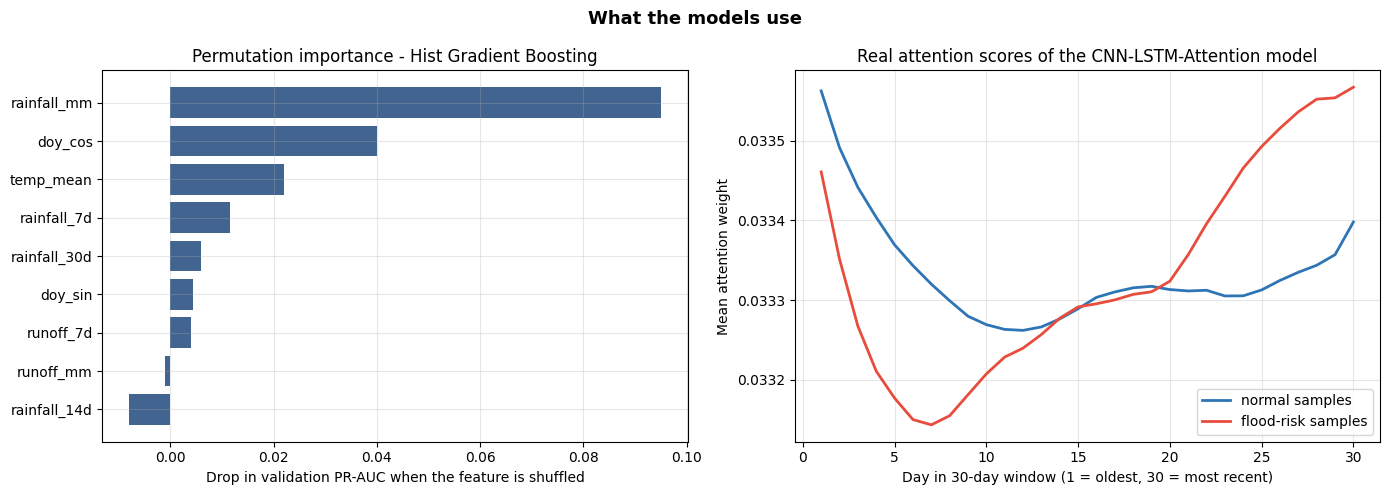

Most important feature for Hist Gradient Boosting: rainfall_mm (PR-AUC drop 0.0951). Near-zero or negative values mean the feature is not used. Attention shows where a model looks, not cause and effect.


In [ ]:
rs = np.random.RandomState(SEED)
base_pr = average_precision_score(y_val, p_val[FINAL]); imp = {}
for j, f in enumerate(FEATURES):                 # permutation importance of the FINAL model, on validation data
    drops = []
    for rep in range(3):
        Xp = X_val.copy(); Xp[:, :, j] = X_val[rs.permutation(len(X_val)), :, j]
        drops.append(base_pr - average_precision_score(y_val, PRED[FINAL](Xp)))
    imp[f] = float(np.mean(drops))
imp = pd.Series(imp).sort_values()
ncols = 2 if attn_viz is not None else 1
fig, axes = plt.subplots(1, ncols, figsize=(7 * ncols, 5)); axes = np.atleast_1d(axes); fig.suptitle('What the models use', fontsize=13, fontweight='bold')
axes[0].barh(imp.index, imp.values, color=COLORS[0], alpha=0.85); axes[0].set_title(f'Permutation importance - {FINAL}'); axes[0].set_xlabel('Drop in validation PR-AUC when the feature is shuffled')
if attn_viz is not None:
    pos, neg = np.where(y_test == 1)[0], np.where(y_test == 0)[0]
    sel_pos = rs.choice(pos, min(300, len(pos)), replace=False) if len(pos) else pos; sel_neg = rs.choice(neg, min(300, len(neg)), replace=False)
    att = lambda idx: attn_viz.predict(X_test[idx], verbose=0).mean(axis=(0, 1, 2))     # (samples, heads, query days, key days) -> mean per day
    days = np.arange(1, SEQ_LEN + 1); axes[1].plot(days, att(sel_neg), lw=2, color=COLORS[1], label='normal samples')
    if len(sel_pos): axes[1].plot(days, att(sel_pos), lw=2, color=COLORS[2], label='flood-risk samples')
    axes[1].set_title('Real attention scores of the CNN-LSTM-Attention model'); axes[1].set_xlabel('Day in 30-day window (1 = oldest, 30 = most recent)'); axes[1].set_ylabel('Mean attention weight'); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/explainability.png', dpi=120, bbox_inches='tight'); plt.show()
print(f'Most important feature for {FINAL}: {imp.index[-1]} (PR-AUC drop {imp.iloc[-1]:.4f}). Near-zero or negative values mean the feature is not used. Attention shows where a model looks, not cause and effect.')

---
## 10. Testing and edge cases
Tests below run on the real functions of this notebook. Each row records the problem, the fix, and whether the test passed in this run.

In [ ]:
def expect_error(fn, exc):
    try:
        fn()
    except exc:
        return
    raise AssertionError(f'{exc.__name__} was not raised')


def t_config():
    expect_error(lambda: validate_config({'X': (200, 10)}, 'runoff', START_DATE, END_DATE, TRAIN_END, VAL_END, SEQ_LEN, HORIZON, PCT), ValueError)
    expect_error(lambda: validate_config(LOCATIONS, 'runoff', END_DATE, START_DATE, TRAIN_END, VAL_END, SEQ_LEN, HORIZON, PCT), ValueError)


def t_missing_col():
    expect_error(lambda: validate_weather_df(raw[first].drop(columns=['rainfall_mm']), 100), ValueError)


def t_short_series():
    expect_error(lambda: validate_weather_df(raw[first].head(10), 100), ValueError)


def t_negative_and_gap():
    d = raw[first].head(200).copy(); d.iloc[5, 0] = -7.0; d.iloc[20:22, 1] = np.nan
    out = validate_weather_df(d, 100)
    assert out['rainfall_mm'].min() >= 0, 'negative rainfall not removed'
    assert not out['temp_max_c'].iloc[20:22].isna().any(), 'short gap not interpolated'


def t_constant_series():
    d = raw[first].head(900).copy(); d['rainfall_mm'] = 0.0
    expect_error(lambda: make_labels(add_features(d), 'runoff_mm', train_end=d.index[700]), ValueError)


def t_short_prediction_input():
    expect_error(lambda: predict_flood_risk(raw[first].tail(20)), ValueError)


def t_api_failure():
    import openmeteo_requests
    real = openmeteo_requests.Client
    class Broken:
        def __init__(self, session=None): pass
        def weather_api(self, *a, **k): raise ConnectionError('simulated network failure')
    openmeteo_requests.Client = Broken
    try:
        expect_error(lambda: fetch_weather('__test_loc__', 34.0, 73.0), RuntimeError)
        assert not os.path.exists(os.path.join(DATA_DIR, '__test_loc___weather.csv')), 'a file/synthetic data was created after failure'
    finally:
        openmeteo_requests.Client = real


def t_no_leakage():
    assert scaler.n_samples_seen_ == train_rows.shape[0], 'scaler saw more than the training rows'
    assert date_train.max() <= pd.Timestamp(TRAIN_END) < date_all[m_va].min() and date_all[m_va].max() <= pd.Timestamp(VAL_END) < date_test.min(), 'split periods overlap'


TESTS = [
    ('Invalid configuration (bad coordinates / dates)', 'Old notebook accepted any settings', 'validate_config raises ValueError', t_config),
    ('Weather table missing a required column', 'Crash deep inside feature code', 'validate_weather_df checks columns first', t_missing_col),
    ('Too little weather data', 'Cryptic shape errors', 'Minimum-length check with clear message', t_short_series),
    ('Negative rainfall and short gaps', 'Bad values flowed into the model', 'Negative -> 0; gaps up to 3 days interpolated', t_negative_and_gap),
    ('Constant / completely dry series', 'Quantile was 0, so every day was labelled flood (found in my own test run)', 'Minimum threshold + error if too few flood-risk days', t_constant_series),
    ('Prediction input shorter than 59 days', 'Silent wrong window', 'predict_flood_risk raises ValueError', t_short_prediction_input),
    ('API failure', 'Old notebook silently generated synthetic data', 'RuntimeError, nothing is invented or saved', t_api_failure),
    ('Data leakage check', 'Old notebook fitted the scaler on all data', 'Scaler fitted on training rows only; periods do not overlap', t_no_leakage),
]


def predict_flood_risk(recent_weather, model_name=None):
    """Predict next-day flood risk from the most recent daily weather (at least 59 days, columns = COLS, index = date).
    Returns probability, level and message. Classroom model: decision support only."""
    name = model_name or FINAL
    df = validate_weather_df(recent_weather, min_rows=MIN_DAYS)
    feats = add_features(df)
    if len(feats) < SEQ_LEN:
        raise ValueError('Not enough clean days after removing missing values.')
    X = scaler.transform(feats[FEATURES].values[-SEQ_LEN:]).astype('float32')[None]
    p = float(PRED[name](X)[0]) if name in PRED else float('nan')
    level = 'WARNING' if p >= THR[name] else ('WATCH' if p >= 0.5 * THR[name] else 'LOW')
    return {'as_of': str(feats.index[-1].date()), 'model': name, 'probability': round(p, 3), 'threshold': round(THR[name], 3), 'level': level,
            'message': f'{level}: estimated flood-risk probability {p:.0%} for the next day (decision support only, not an official warning).'}


rows = []
for title, problem, fix, fn in TESTS:
    try:
        fn(); res = 'PASS'
    except Exception as e:
        res = f'FAIL ({type(e).__name__}: {e})'
    rows.append({'edge case': title, 'problem found': problem, 'fix': fix, 'result': res})
tests_df = pd.DataFrame(rows); print(tests_df.to_string(index=False)); tests_df.to_csv(f'{OUT_DIR}/edge_case_tests.csv', index=False)
print(f"\n{(tests_df['result'] == 'PASS').sum()} of {len(tests_df)} tests passed.")

                                      edge case                                                              problem found                                                         fix result
Invalid configuration (bad coordinates / dates)                                         Old notebook accepted any settings                           validate_config raises ValueError   PASS
        Weather table missing a required column                                             Crash deep inside feature code                    validate_weather_df checks columns first   PASS
                        Too little weather data                                                       Cryptic shape errors                     Minimum-length check with clear message   PASS
               Negative rainfall and short gaps                                           Bad values flowed into the model               Negative -> 0; gaps up to 3 days interpolated   PASS
               Constant / completely dry series Qu

---
## 11. Working demo
`predict_flood_risk()` takes the last 59+ days of weather and returns a risk level. Below it is replayed on a real day from the test period, followed by a clearly labelled **what-if scenario**
(extra rain added by hand). The scenario is hypothetical and is not data.

In [ ]:
test_dates_loc0 = date_test[loc_test == 0]
best_day = test_dates_loc0[int(np.argmax(p_test[FINAL][loc_test == 0]))]
recent = raw[first].loc[:best_day - pd.Timedelta(days=HORIZON)].tail(70)
print('REAL REPLAY -', first, '- day with the highest predicted risk in the test period'); print(predict_flood_risk(recent)['message'], '| prediction date:', best_day.date())
quiet_day = test_dates_loc0[int(np.argmin(p_test[FINAL][loc_test == 0]))]
print('REAL REPLAY - lowest-risk day:', predict_flood_risk(raw[first].loc[:quiet_day - pd.Timedelta(days=HORIZON)].tail(70))['message'])
what_if = recent.copy(); what_if.iloc[-2:, what_if.columns.get_loc('rainfall_mm')] += 40
print('WHAT-IF (hypothetical: +40 mm of rain on each of the last 2 days):', predict_flood_risk(what_if)['message'])

RUN_DEMO = False          # True = open a small web demo (Gradio)
if RUN_DEMO:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'], check=False)
    import gradio as gr
    def demo_fn(location, date_str, extra_rain):
        d = raw[location].loc[:pd.Timestamp(date_str)].tail(70).copy()
        d.iloc[-2:, d.columns.get_loc('rainfall_mm')] += float(extra_rain)
        return predict_flood_risk(d)['message']
    gr.Interface(fn=demo_fn, inputs=[gr.Dropdown(list(raw), value=first, label='Location'), gr.Textbox(value=str(best_day.date()), label='Date (YYYY-MM-DD)'),
                 gr.Slider(0, 100, value=0, label='What-if: extra rain on each of the last 2 days (mm)')], outputs='text', title='Flood-risk demo (classroom model)').launch(share=True)

REAL REPLAY - Havelian - day with the highest predicted risk in the test period
REAL REPLAY - lowest-risk day: LOW: estimated flood-risk probability 1% for the next day (decision support only, not an official warning).
WHAT-IF (hypothetical: +40 mm of rain on each of the last 2 days): WARNING: estimated flood-risk probability 91% for the next day (decision support only, not an official warning).


---
## 12. Recommendation, limitations and project log

In [ ]:
print('RECOMMENDATION TO THE STAKEHOLDER')
print(f"  The final model ({FINAL}) can be used as a *screening aid*: it ranks days by next-day flood-risk so staff know when to look more closely.")
print(f"  On the untouched test years it reached recall {fr['recall']:.0%} with a {fr['false alarm rate']:.0%} false-alarm rate (success criteria: {'both met' if sc1 and sc2 else 'NOT all met - see Section 8'}).")
print('\nIT MUST NOT BE USED FOR: official flood warnings, evacuation decisions, insurance or any other high-stakes decision.')
print('\nLIMITATIONS')
for t in ['The label is derived from calculated runoff (or simulated GloFAS discharge), not from verified flood records or river-gauge data.',
          'Curve Number is one typical value (CN = 75), not calibrated per catchment; older reanalysis data is coarser.',
          'Only next-day prediction from past weather: no weather forecasts are used, so it is not a multi-day early-warning system.',
          'Only a few locations in one region; results may not transfer to other basins.',
          'Few flood-risk days, so recall values are noisy; differences between models can be within random variation.',
          'Fairness/privacy: no personal data is used. Coverage is limited to the chosen locations, so other communities are not represented.']:
    print('  -', t)
print('\nFURTHER VALIDATION NEEDED BEFORE ANY REAL USE: documented flood events or gauge data as labels, more catchments, forecast inputs, expert review, and a pilot with the stakeholder.')

RECOMMENDATION TO THE STAKEHOLDER
  The final model (Hist Gradient Boosting) can be used as a *screening aid*: it ranks days by next-day flood-risk so staff know when to look more closely.
  On the untouched test years it reached recall 69% with a 18% false-alarm rate (success criteria: NOT all met - see Section 8).

IT MUST NOT BE USED FOR: official flood warnings, evacuation decisions, insurance or any other high-stakes decision.

LIMITATIONS
  - The label is derived from calculated runoff (or simulated GloFAS discharge), not from verified flood records or river-gauge data.
  - Curve Number is one typical value (CN = 75), not calibrated per catchment; older reanalysis data is coarser.
  - Only next-day prediction from past weather: no weather forecasts are used, so it is not a multi-day early-warning system.
  - Only a few locations in one region; results may not transfer to other basins.
  - Few flood-risk days, so recall values are noisy; differences between models can be within ra

### Project log: errors found and how they were fixed
| # | Problem found | Fix |
|---|---|---|
| 1 | Scaler and flood threshold were fitted on the whole dataset (future data leaked in) | Split by date first; both fitted on the training period only |
| 2 | Training data was randomly cut to 15,000 samples; one location, 1993-2024 | Longer period, several locations, no cap |
| 3 | Only 15% of flood-risk days were caught; threshold fixed at 0.5; probabilities smoothed before scoring | Raw probabilities, validation-chosen threshold, PR-AUC/recall reported, baselines added |
| 4 | "Attention weights" and "feature importance" were hand-made numbers | Real attention scores and permutation importance |
| 5 | Silent fallback to synthetic data if the API failed | Clear error; downloaded data cached as CSV |
| 6 | On a dry series the 95th percentile was 0, so every day became a "flood" (found in my own test run) | Minimum threshold and an error when there are too few flood-risk days |
| 7 | API timestamps were not aligned to the local calendar day | Offset applied and dates rounded to the day |
| 8 | 2022 section claimed "validation" using model-derived labels | Renamed and explained honestly |

In [ ]:
# ---------------- save artifacts + environment file ----------------
import joblib
art = os.path.join(OUT_DIR, 'model_artifacts'); os.makedirs(art, exist_ok=True)
joblib.dump({'scaler': scaler, 'features': FEATURES, 'seq_len': SEQ_LEN, 'baseline_lr': lr, 'random_forest': rf_tuned, 'hist_gb': hgb, 'best_feature_set': BEST_FEAT}, f'{art}/sklearn_models.joblib')
json.dump({'final_model': FINAL, 'thresholds': THR, 'label_source': LABEL_SOURCE, 'locations': LOCATIONS, 'train_end': TRAIN_END, 'val_end': VAL_END}, open(f'{art}/settings.json', 'w'), indent=2)
for n, m in dl_models.items():
    m.save(f'{art}/{n.replace("-", "_")}.keras')
pkgs = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'imbalanced-learn', 'scipy', 'requests', 'openmeteo-requests', 'requests-cache', 'retry-requests', 'joblib'] + (['tensorflow'] if RUN_DL else [])
req = []
for p_ in pkgs:
    try:
        req.append(f'{p_}=={md.version(p_)}')
    except md.PackageNotFoundError:
        pass
open(f'{OUT_DIR}/requirements.txt', 'w').write('\n'.join(req) + '\n')
print('Saved results, figures, models and requirements.txt in:', OUT_DIR); print('\n'.join(req))

Saved results, figures, models and requirements.txt in: flood_outputs
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
imbalanced-learn==0.14.2
scipy==1.16.3
requests==2.32.4
openmeteo-requests==1.7.5
requests-cache==1.3.3
retry-requests==2.0.0
joblib==1.6.0
tensorflow==2.21.0
